In [1]:
import os
from ase.io import read
from ase.visualize import view
import matplotlib.pyplot as plt
import numpy as np
import h5py

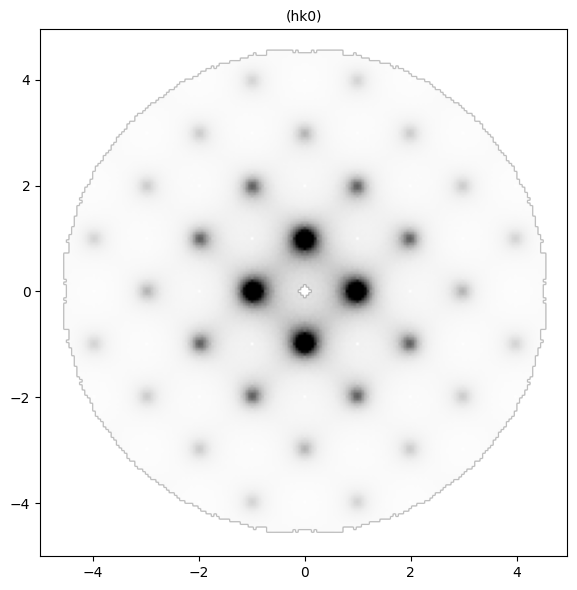

In [5]:
h5_filename = os.path.join("fe-al/mc/mc_diffuse/masked_diffuse_intensity.h5")

with h5py.File(h5_filename, "r") as f:
    data_3d = f["data"][:]
    lower_limits = f["lower_limits"][:]  
    step_sizes = f["step_sizes"][:]      

# setting up coordinates axes from reciprocal space data
shape_h, shape_k, shape_l = data_3d.shape
h_axis = lower_limits[0] + np.arange(shape_h) * step_sizes[0]
k_axis = lower_limits[1] + np.arange(shape_k) * step_sizes[1]
l_axis = lower_limits[2] + np.arange(shape_l) * step_sizes[2]

l_center_idx = data_3d.shape[2] // 2  # midpoint of L axis corresponds to L=0 plane
hk0_slice = data_3d[:, :, l_center_idx]

plot_filename = os.path.join("fe-al_hk0_slice.png")
plt.figure(figsize=(7, 6))
plt.imshow(
    hk0_slice, 
    cmap='Greys', 
    origin='lower',
    extent=[h_axis.min(), h_axis.max(), k_axis.min(), k_axis.max()],
    aspect='equal',
    vmin=0, vmax=1000000
)
# plt.colorbar(label='Diffuse Scattering Intensity')
# plt.title(f'Fe-Al Thermal Diffuse Scattering (Ensemble Average)\n(HK0) Plane')
plt.title(f'(hk0)', fontsize = 10)
# plt.xlabel('$H$ (r.l.u.)')
# plt.ylabel('$K$ (r.l.u.)')
plt.xticks(np.arange(-4, 5, 2))
plt.yticks(np.arange(-4, 5, 2))
plt.tight_layout()
# plt.savefig(plot_filename, dpi=300) 
plt.show()

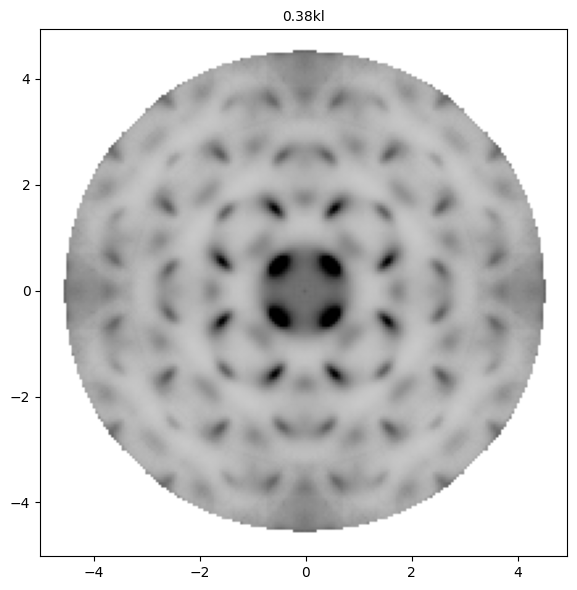

In [2]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

h5_filename = os.path.join("experiment.h5")

with h5py.File(h5_filename, "r") as f:
    data_3d = f["data"][:]
    lower_limits = f["lower_limits"][:]  
    step_sizes = f["step_sizes"][:]      

shape_h, shape_k, shape_l = data_3d.shape
h_axis = lower_limits[0] + np.arange(shape_h) * step_sizes[0]
k_axis = lower_limits[1] + np.arange(shape_k) * step_sizes[1]
l_axis = lower_limits[2] + np.arange(shape_l) * step_sizes[2]

# find index along h axis closest to experiment
target_h = 0.3833
h_idx = np.argmin(np.abs(h_axis - target_h))
actual_h = h_axis[h_idx]  # actual value on the grid

# extract the xkl slice
xkl_slice = data_3d[h_idx, :, :].T

plot_filename = os.path.join("fe-al_0.3833kl_slice.png")
plt.figure(figsize=(7, 6))
plt.imshow(
    xkl_slice, 
    cmap='Greys', 
    origin='lower',
    extent=[k_axis.min(), k_axis.max(), l_axis.min(), l_axis.max()],
    aspect='equal',
    vmin=0, vmax=2#np.max(xkl_slice) * 0.7
)
# plt.colorbar(label='Diffuse Scattering Intensity')
# plt.title(f'Fe-Al Thermal Diffuse Scattering (Ensemble Average)\n({actual_h:.2f}KL) Plane')
plt.title(f'{actual_h:.2f}kl', fontsize = 10)
# plt.xlabel('$K$ (r.l.u.)')
# plt.ylabel('$L$ (r.l.u.)')
plt.xticks(np.arange(-4, 5, 2))
plt.yticks(np.arange(-4, 5, 2))
plt.tight_layout()
# plt.savefig(plot_filename, dpi=300) 
plt.show()

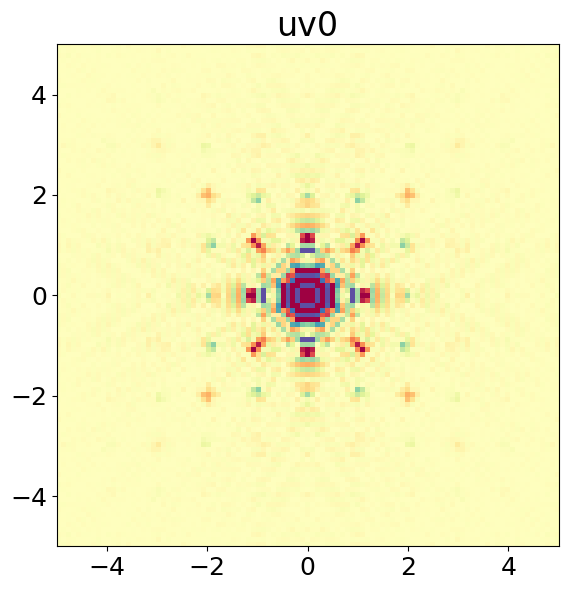

In [ ]:
h5_filename = os.path.join("main/yell_refinement/exp-delta-pdf.h5")

with h5py.File(h5_filename, "r") as f:
    data_3d = f["data"][:]
    lower_limits = f["lower_limits"][:]  
    step_sizes = f["step_sizes"][:]      

# setting up coordinates axes from reciprocal space data
shape_u, shape_v, shape_w = data_3d.shape
u_axis = lower_limits[0] + np.arange(shape_u) * step_sizes[0]
v_axis = lower_limits[1] + np.arange(shape_v) * step_sizes[1]
w_axis = lower_limits[2] + np.arange(shape_w) * step_sizes[2]

# select plane slice closest to the w=0 plane
w_zero_idx = np.argmin(np.abs(w_axis))
uv0_slice = data_3d[:, :, w_zero_idx].T

# color map made to match density viewer (https://github.com/aglie/DensityViewer)
color_saturation = 10
color_stops = np.array(
    [
        (94, 79, 162), (50, 136, 189), (102, 194, 165), (171, 221, 164),
        (230, 245, 152), (255, 255, 191), (254, 224, 139), (253, 174, 97),
        (244, 109, 67), (213, 62, 79), (158, 1, 66),
    ],
    dtype=float,
 )

normalized = np.clip((uv0_slice + color_saturation) / (2 * color_saturation), 0, 1)
color_position = normalized * (len(color_stops) - 1)
lower_color = np.floor(color_position).astype(int)
upper_color = np.ceil(color_position).astype(int)
color_weight = (color_position - lower_color)[..., np.newaxis]
rgb_slice = (1 - color_weight) * color_stops[lower_color] + color_weight * color_stops[upper_color]
rgb_slice = np.floor(rgb_slice).astype(np.uint8)

plot_filename = os.path.join("fe-al_uv0_slice.png")
plt.figure(figsize=(7, 6))
plt.imshow(
    rgb_slice, 
    origin="lower",
    extent=[u_axis.min(), u_axis.max(), v_axis.min(), v_axis.max()],
    aspect="equal",
    interpolation="nearest",
)
# plt.colorbar(label="Diffuse Scattering Intensity")
# plt.title(f"Fe-Al Thermal Diffuse Scattering (Ensemble Average)\n(HK0) Plane")
plt.title("uv0", fontsize=24)
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.xticks(np.arange(-4, 5, 2), fontsize=18)
plt.yticks(np.arange(-4, 5, 2), fontsize=18)
plt.tight_layout()
# plt.savefig(plot_filename, dpi=300) 
plt.show()

In [7]:
atoms = read("fe-al_md_structures/final_structures/md_relaxed_frame_001.cif")
current_symbols = atoms.get_chemical_symbols()
print(f"Total atoms in supercell: {len(atoms)}")
print(f"Fe count:           {current_symbols.count('Fe')}")
print(f"Al count:           {current_symbols.count('Al')}")

print(atoms)
view(atoms, viewer='x3d')

Total atoms in supercell: 2000
Fe count:           1600
Al count:           400
Atoms(symbols='Al400Fe1600', pbc=True, cell=[28.67, 28.67, 28.67], spacegroup_kinds=...)
